In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os

In [2]:
# Operators
def grad2(F, dx, dy):
    return (
        np.gradient(F, dx, axis=0, edge_order=2),
        np.gradient(F, dy, axis=1, edge_order=2),
    )

def lap2(F, dx, dy):
    Fx, Fy = grad2(F, dx, dy)
    return (
        np.gradient(Fx, dx, axis=0, edge_order=2)
        + np.gradient(Fy, dy, axis=1, edge_order=2)
    )

def A_of_F(rho_l, F, dx, dy):
    rho_x, rho_y = grad2(rho_l, dx, dy)
    F_x, F_y = grad2(F, dx, dy)
    return rho_x * F_x + rho_y * F_y + rho_l * lap2(F, dx, dy)


# Gaussian kernel and derivatives
def gaussian_kernel(X, Z, sigma):
    X2 = np.sum(X**2, axis=1)[:, None]
    Z2 = np.sum(Z**2, axis=1)[None, :]
    r2 = np.maximum(X2 + Z2 - 2.0 * X @ Z.T, 0.0)
    return np.exp(-r2 / (2.0 * sigma**2))

def hermite_derivatives_1d(r, sigma):
    s2 = sigma**2
    return [
        np.ones_like(r),
        -r / s2,
        r**2 / s2**2 - 1.0 / s2,
        3.0*r / s2**2 - r**3 / s2**3,
        r**4 / s2**4 - 6.0*r**2 / s2**3 + 3.0 / s2**2,
    ]

def gaussian_mixed_derivative(X, Z, sigma, ax, ay, bz, by):
    r1 = X[:, None, 0] - Z[None, :, 0]
    r2 = X[:, None, 1] - Z[None, :, 1]
    K = np.exp(-(r1**2 + r2**2) / (2.0 * sigma**2))
    h1 = hermite_derivatives_1d(r1, sigma)
    h2 = hermite_derivatives_1d(r2, sigma)
    return (-1.0)**(bz + by) * h1[ax + bz] * h2[ay + by] * K

def Ax_kernel_eval(X_eval, Z, rho_eval, rhox_eval, rhoy_eval, sigma):
    Dx1 = gaussian_mixed_derivative(X_eval, Z, sigma, 1, 0, 0, 0)
    Dx2 = gaussian_mixed_derivative(X_eval, Z, sigma, 0, 1, 0, 0)
    Dxx = gaussian_mixed_derivative(X_eval, Z, sigma, 2, 0, 0, 0)
    Dyy = gaussian_mixed_derivative(X_eval, Z, sigma, 0, 2, 0, 0)
    return rhox_eval[:, None]*Dx1 + rhoy_eval[:, None]*Dx2 + rho_eval[:, None]*(Dxx + Dyy)

# Errors
def rel_l2_interval(F, G, X1, X2, R, dx=None, dy=None):
    mask = (np.abs(X1) <= R) & (np.abs(X2) <= R)
    num = np.sum((F[mask] - G[mask])**2)
    den = np.sum(G[mask]**2)
    if dx is not None and dy is not None:
        num *= dx * dy
        den *= dx * dy
    return np.sqrt(num / den)

def weighted_rel_l2(F, G, weight):
    return np.sqrt(np.sum(weight * (F - G)**2) / np.sum(weight * G**2))

def operator_residual(rho, f_delta, V_hat, time_ids, dx, dy):
    A_Vhat = np.zeros_like(rho)
    for l in time_ids:
        A_Vhat[l] = A_of_F(rho[l], V_hat, dx, dy)
    return np.sqrt(
        np.sum(rho[time_ids] * (A_Vhat[time_ids] - f_delta[time_ids])**2)
        /
        np.sum(rho[time_ids] * f_delta[time_ids]**2)
    ), A_Vhat

# Sampling and estimator

def prepare_samples(data, rho_cutoff=1e-7):
    rho = data["rho"].astype(np.float64)
    phi = data["phi"].astype(np.float64)
    V_true = data["V_true"].astype(np.float64)
    x1, x2 = data["x1_obs"], data["x2_obs"]
    dx, dy = float(data["dx"]), float(data["dy"])
    dt = float(data["dt"])
    Nt, Nx, Ny = rho.shape
    time_ids = np.arange(1, Nt - 1)
    H_god = data["H_god"].astype(np.float64)
    Uprime_arr = data["Uprime"].astype(np.float64)
    phi_t = np.zeros_like(phi)
    phi_t[1:-1] = (phi[2:] - phi[:-2]) / (2.0 * dt)
    f_delta = np.zeros_like(rho)
    for l in time_ids:
        f_delta[l] = -A_of_F(rho[l], phi_t[l] + H_god[l] + Uprime_arr[l], dx, dy)
    X1, X2 = np.meshgrid(x1, x2, indexing="ij")
    X_flat = np.stack([X1, X2], axis=-1).reshape(-1, 2)
    rho_x = np.zeros_like(rho)
    rho_y = np.zeros_like(rho)
    for l in time_ids:
        rho_x[l], rho_y[l] = grad2(rho[l], dx, dy)
    X_all = np.tile(X_flat, (Nt, 1))
    mask_t = np.zeros((Nt, Nx, Ny), dtype=bool)
    mask_t[time_ids] = True
    mask = (rho.reshape(-1) > rho_cutoff) & mask_t.reshape(-1)
    return dict(
        rho=rho,
        f_delta=f_delta,
        V_true=V_true,
        x1=x1,
        x2=x2,
        dx=dx,
        dy=dy,
        Nt=Nt,
        Nx=Nx,
        Ny=Ny,
        time_ids=time_ids,
        X1=X1,
        X2=X2,
        X_flat=X_flat,
        X_all=X_all[mask],
        rho_all=rho.reshape(-1)[mask],
        rho_x_all=rho_x.reshape(-1)[mask],
        rho_y_all=rho_y.reshape(-1)[mask],
        f_all=f_delta.reshape(-1)[mask],
        rho_bar=np.mean(rho[time_ids], axis=0),
    )

def sample_collocation(S, M=2500, alpha=0.5, seed=123):
    rng = np.random.default_rng(seed)
    rho_all = S["rho_all"]
    prob = alpha * rho_all / rho_all.sum()
    prob += (1.0 - alpha) / len(rho_all)
    prob /= prob.sum()
    idx = rng.choice(len(rho_all), M, replace=False, p=prob)
    return dict(
        Z=S["X_all"][idx],
        rho_c=S["rho_all"][idx],
        rho_x_c=S["rho_x_all"][idx],
        rho_y_c=S["rho_y_all"][idx],
        f_c=S["f_all"][idx],
    )

def fit_sp_estimator(C, sigma=1.2, lam=1e-8, jitter=1e-10):
    Z = C["Z"]
    Kc = gaussian_kernel(Z, Z, sigma)
    Ac = Ax_kernel_eval(
        X_eval=Z,
        Z=Z,
        rho_eval=C["rho_c"],
        rhox_eval=C["rho_x_c"],
        rhoy_eval=C["rho_y_c"],
        sigma=sigma,
    )
    sw = np.sqrt(C["rho_c"])
    Aw = Ac * sw[:, None]
    fw = C["f_c"] * sw
    beta = np.linalg.solve(
        Aw.T @ Aw + lam * Kc + jitter * np.eye(len(Z)),
        Aw.T @ fw,
    )
    return beta

def reconstruct_V(beta, Z, S, sigma=1.2):
    V_hat = (
        gaussian_kernel(S["X_flat"], Z, sigma) @ beta
    ).reshape(S["Nx"], S["Ny"])
    V_hat += (
        np.sum(S["rho_bar"] * (S["V_true"] - V_hat))
        / np.sum(S["rho_bar"])
    )
    return V_hat

# Main runner

def run_sp(data_file, params):
    data = np.load(data_file)
    S = prepare_samples(data, rho_cutoff=params["rho_cutoff"])
    C = sample_collocation(S, M=params["M"], alpha=params["alpha"], seed=params["seed"])
    beta = fit_sp_estimator(C, sigma=params["sigma"], lam=params["lam"], jitter=params["jitter"])
    V_hat = reconstruct_V(beta, C["Z"], S, sigma=params["sigma"])
    err = np.abs(V_hat - S["V_true"])
    for R in [2, 4]:
        print(
            f"[-{R},{R}]^2 relative L2 error = "
            f"{rel_l2_interval(V_hat,S['V_true'],S['X1'],S['X2'],R,S['dx'],S['dy']):.4e}"
        )
    rel_w = weighted_rel_l2(V_hat, S["V_true"], S["rho_bar"])
    rel_res, A_Vhat = operator_residual(
        S["rho"],
        S["f_delta"],
        V_hat,
        S["time_ids"],
        S["dx"],
        S["dy"],
    )
    print("Weighted relative L2 error =", rel_w)
    print("Relative operator residual =", rel_res)
    return {
        "S": S,
        "C": C,
        "beta": beta,
        "V_hat": V_hat,
        "err": err,
        "rel_weighted": rel_w,
        "rel_res": rel_res,
        "A_Vhat": A_Vhat,
    }

# Plots
def crop_box(x1, x2, F, R=4):
    ix = np.abs(x1) <= R
    iy = np.abs(x2) <= R
    return x1[ix], x2[iy], F[np.ix_(ix, iy)]

def plot_surface(x1, x2, F, save_name, R=4):
    x1c, x2c, Fc = crop_box(x1, x2, F, R)
    X1, X2 = np.meshgrid(x1c, x2c, indexing="ij")
    fig = plt.figure(figsize=(6,5))
    ax = fig.add_subplot(111, projection="3d")
    ax.plot_surface(X1, X2, Fc, cmap="viridis", edgecolor="none", antialiased=True)
    ax.view_init(30, -60)
    ax.set_xlabel(r"$x_1$")
    ax.set_ylabel(r"$x_2$")
    plt.tight_layout()
    plt.savefig(save_name, dpi=300, bbox_inches="tight")
    plt.show()

def plot_error(x1, x2, err, save_name, R=4):
    x1c, x2c, errc = crop_box(x1, x2, err, R)

    fig, ax = plt.subplots(figsize=(6, 5))

    im = ax.imshow(
        errc.T,
        origin="lower",
        extent=[-R, R, -R, R],
        cmap="viridis",
        aspect="auto",
        interpolation="nearest",
    )

    ax.set_xlabel(r"$x_1$")
    ax.set_ylabel(r"$x_2$")
    ax.set_xlim(-R, R)
    ax.set_ylim(-R, R)

    fig.colorbar(im, ax=ax, label=r"$|V-\widehat V|$")

    fig.savefig(save_name, dpi=300, bbox_inches="tight", pad_inches=0.02)
    plt.show()

def plot_results(R, tag="sp", outdir="figures"):
    S = R["S"]
    x1, x2 = S["x1"], S["x2"]
    V_true = S["V_true"]
    V_hat = R["V_hat"]
    err = np.abs(V_hat - V_true)
    i0 = len(x1)//2
    j0 = len(x2)//2
    plot_surface(x1, x2, V_true, f"{outdir}/V_true_{tag}.png")
    plot_surface(x1, x2, V_hat, f"{outdir}/kernel_V_hat_{tag}.png")
    plot_error(x1, x2, err, f"{outdir}/kernel_error_{tag}.png")

    plt.figure(figsize=(7,4.5))
    plt.plot(x1, V_true[:,j0], lw=2, label="True")
    plt.plot(x1, V_hat[:,j0], "--", lw=2, label="Estimated")
    plt.xlabel(r"$x_1$")
    plt.ylabel(r"$V(x_1,0)$")
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"{outdir}/kernel_V_slice_x1_{tag}.png", dpi=300, bbox_inches="tight")
    plt.show()

    plt.figure(figsize=(7,4.5))
    plt.plot(x2, V_true[i0,:], lw=2, label="True")
    plt.plot(x2, V_hat[i0,:], "--", lw=2, label="Estimated")
    plt.xlabel(r"$x_2$")
    plt.ylabel(r"$V(0,x_2)$")
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"{outdir}/kernel_V_slice_x2_{tag}.png", dpi=300, bbox_inches="tight",)
    plt.show()

[-2,2]^2 relative L2 error = 4.6703e-03
[-4,4]^2 relative L2 error = 1.1454e-02
Weighted relative L2 error = 0.01631132845818257
Relative operator residual = 0.00482963270007981


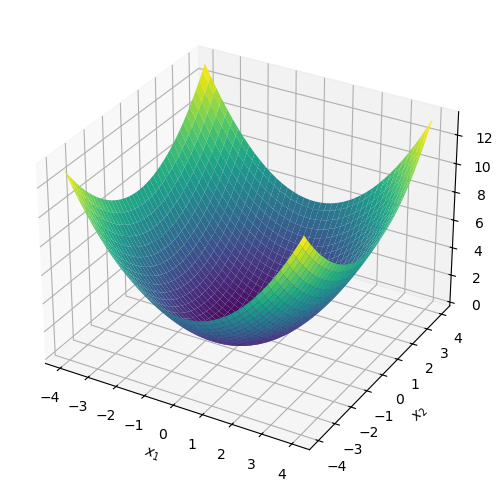

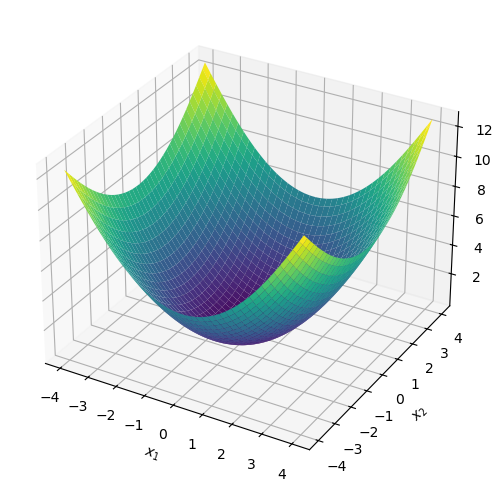

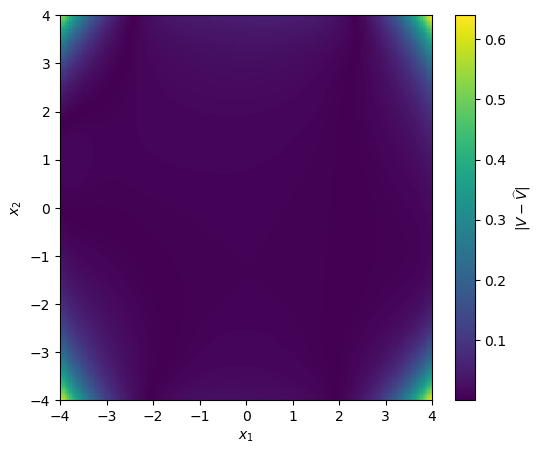

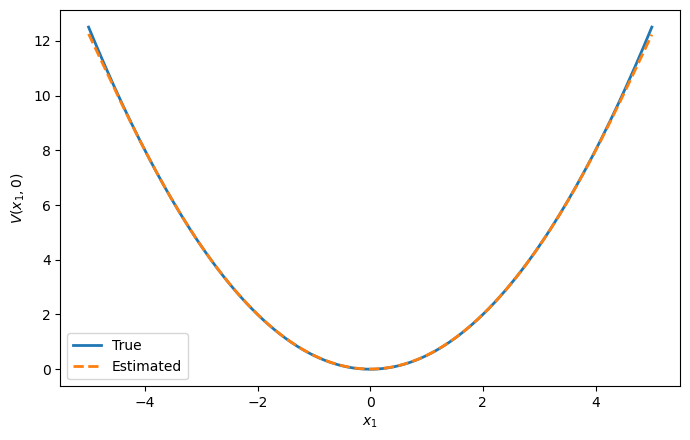

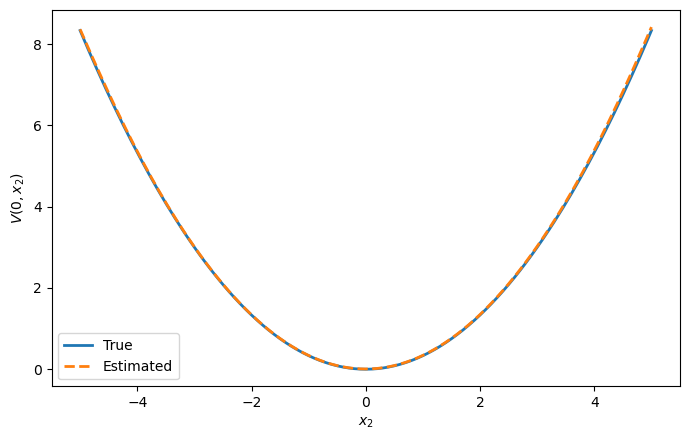

In [3]:
# example 3:  polynomial potential
os.makedirs("figures_polynomial", exist_ok=True)
data_file = "data/example3_whf_polynomial_Cx5_Ct50.npz"

params = dict(
    M=8000,
    sigma=2.0,
    lam=1e-8,
    alpha=0.5,
    rho_cutoff=1e-5,
    seed=123,
    jitter=1e-10,
)

R = run_sp(data_file, params)
plot_results(R, tag="example3_sp", outdir="figures_polynomial")

[-2,2]^2 relative L2 error = 2.5832e-03
[-4,4]^2 relative L2 error = 2.7633e-02
Weighted relative L2 error = 0.025699724906277473
Relative operator residual = 0.003837274738279822


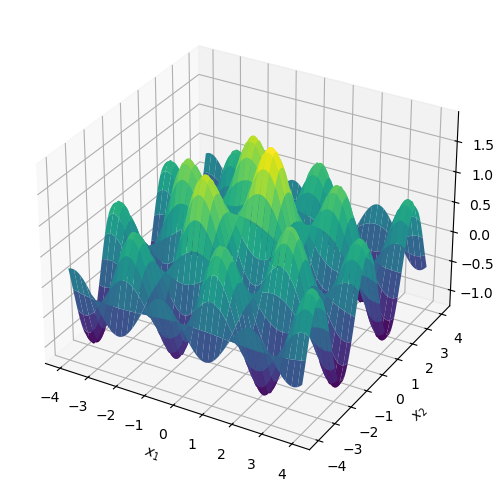

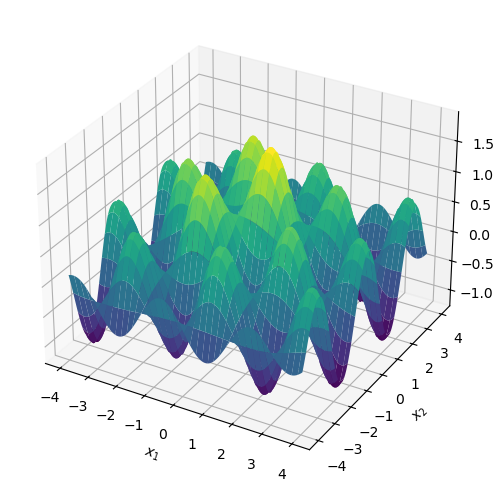

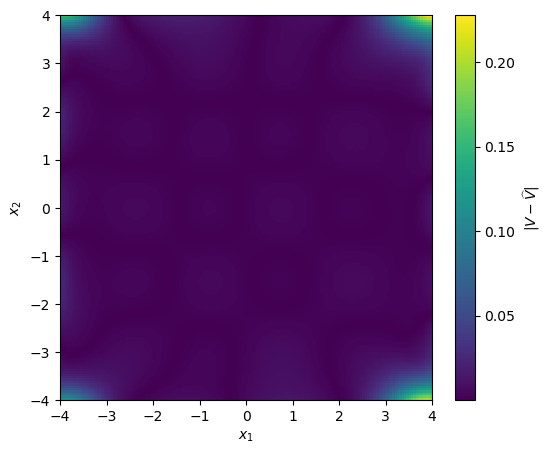

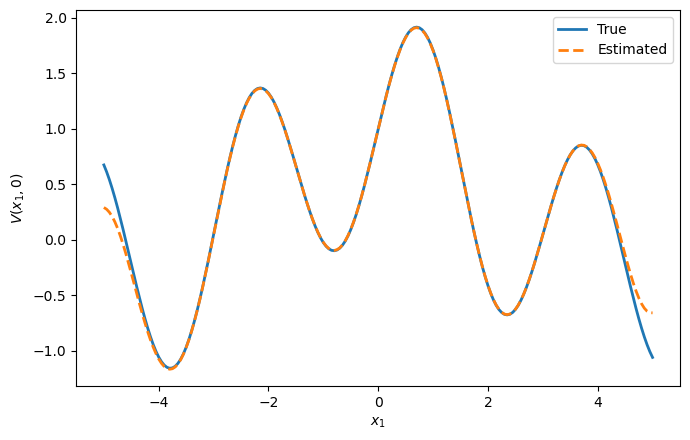

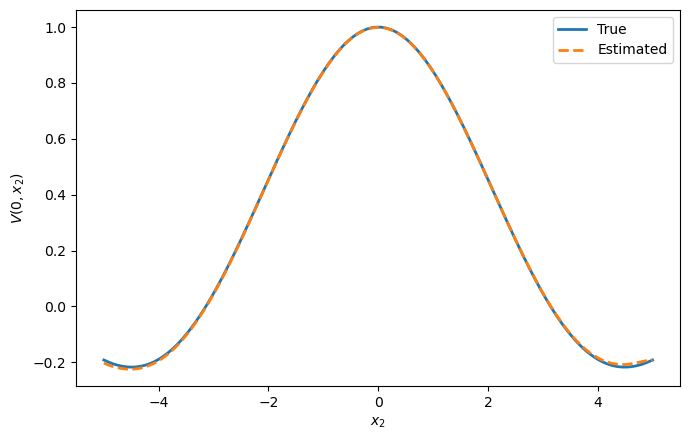

In [4]:
# example 4:  highly_nonconvex potential
os.makedirs("figures_highly_nonconvex", exist_ok=True)
data_file = "data/example4_whf_highly_nonconvex_Cx5_Ct50.npz"

params = dict(
    M=8000,
    sigma=0.4,
    lam=1e-7,
    alpha=0.5,
    rho_cutoff=1e-5,
    seed=123,
    jitter=1e-10,
)

R = run_sp(data_file, params)
plot_results(R, tag="example4_sp", outdir="figures_highly_nonconvex")